In [1]:
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import pearsonr

In [2]:
freq_data = pd.read_csv("1000G.EUR.1_freqs.afreq", sep="\t")
maf = freq_data["ALT_FREQS"].apply(lambda x: 1 - x if x > 0.5 else x)

common = (maf > 0.05).sum()
low_freq = ((maf >= 0.01) & (maf <= 0.05)).sum()
rare = (maf < 0.01).sum()
total = len(maf)

print(f"Common variants (>0.05): {common} ({common / total:.4f})")
print(f"Low-frequency variants (0.01-0.05): {low_freq} ({low_freq / total:.4f})")
print(f"Rare variants (<0.01): {rare} ({rare / total:.4f})")

Common variants (>0.05): 88107 (0.8932)
Low-frequency variants (0.01-0.05): 9300 (0.0943)
Rare variants (<0.01): 1235 (0.0125)


In [3]:
fam_data = pd.read_csv("1000G.EUR.22.fam", sep=r"\s+", header=None)
expr_data = pd.read_csv(
    "GD462.GeneQuantRPKM.50FN.samplename.resk10.txt.gz", sep="\t"
)

# Sort explicitly to guarantee deterministic ordering across runs
common_ids = sorted(list(set(fam_data[0]).intersection(set(expr_data.columns))))
print(f"Overlapping samples: {len(common_ids)}")

expr_filtered = expr_data[
    ["TargetID", "Gene_Symbol", "Chr", "Coord"] + common_ids
]
fam_filtered = fam_data[fam_data[0].isin(common_ids)]

Overlapping samples: 344


In [4]:
gene_info = expr_data[expr_data["Chr"].astype(str).str.contains("22")].iloc[0]
target_gene = gene_info["Gene_Symbol"]
start = max(0, int(gene_info["Coord"]) - 500000)
end = int(gene_info["Coord"]) + 500000

with open("my_coord.txt", "w") as f:
  f.write(f"22\t{start}\t{end}\t{target_gene}\n")

print(f"Target Gene: {target_gene} (Chr 22: {start} - {end})")

Target Gene: ENSG00000249263.2 (Chr 22: 16640518 - 17640518)


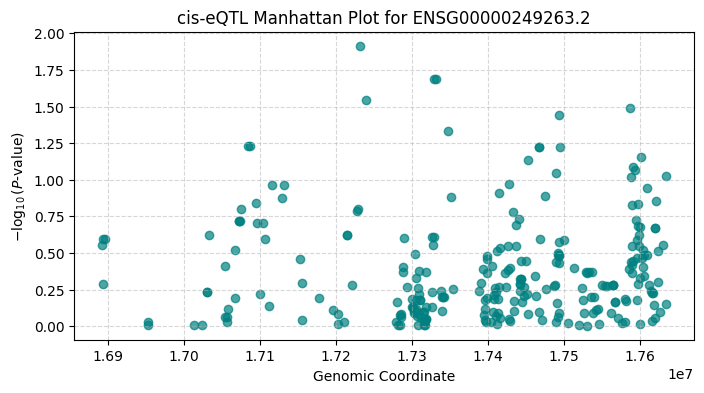

In [5]:
geno_data = pd.read_csv("1000G.EUR.22.GeneX_raw.raw", sep=r"\s+")
gene_expression = (
    expr_filtered[expr_filtered["Gene_Symbol"] == target_gene]
    .iloc[0][common_ids]
    .astype(float)
)

geno_filtered = geno_data[geno_data["IID"].astype(str).isin(common_ids)].set_index(
    "IID"
)
geno_filtered.index = geno_filtered.index.astype(str)
geno_filtered = geno_filtered.loc[gene_expression.index]

p_values = []
snp_names = geno_filtered.columns[6:]

for snp in snp_names:
  X = sm.add_constant(geno_filtered[snp])
  model = sm.OLS(gene_expression, X, missing="drop").fit()
  p_values.append(model.pvalues[snp])

results = pd.DataFrame({"SNP": snp_names, "P_value": p_values})

bim_data = pd.read_csv("1000G.EUR.22.GeneX.bim", sep=r"\s+", header=None)
bim_data.columns = ["CHR", "SNP_base", "CM", "Position", "A1", "A2"]

results["SNP_base"] = results["SNP"].apply(lambda x: x.rsplit("_", 1)[0])
results = results.merge(
    bim_data[["SNP_base", "Position"]], on="SNP_base", how="inner"
)
results["-log10(P)"] = -np.log10(results["P_value"])

plt.figure(figsize=(8, 4))
plt.scatter(results["Position"], results["-log10(P)"], color="teal", alpha=0.7)
plt.xlabel("Genomic Coordinate")
plt.ylabel(r"$-\log_{10}(P\text{-value})$")
plt.title(f"cis-eQTL Manhattan Plot for {target_gene}")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [6]:
# Generate reference frequency file to prevent PLINK 2 sample-size truncation errors (<50 samples)
subprocess.run(
    [
        "./plink2_folder/plink2",
        "--bfile",
        "1000G.EUR.22.GeneX",
        "--freq",
        "--out",
        "1000G.EUR.22.GeneX",
    ],
    capture_output=True,
)

CompletedProcess(args=['./plink2_folder/plink2', '--bfile', '1000G.EUR.22.GeneX', '--freq', '--out', '1000G.EUR.22.GeneX'], returncode=3, stdout=b'PLINK v2.0.0-b.1-dev M1 (7 Oct 2026)                cog-genomics.org/plink/2.0/\n(C) 2005-2026 S Purcell, C Chang, B Demaille      GNU General Public License v3\nLogging to 1000G.EUR.22.GeneX.log.\nOptions in effect:\n  --bfile 1000G.EUR.22.GeneX\n  --freq\n  --out 1000G.EUR.22.GeneX\n\nStart time: Fri Nov  6 13:42:07 2026\n16384 MiB RAM detected; reserving 8192 MiB for main workspace.\nUsing up to 8 compute threads.\nEnd time: Fri Nov  6 13:42:07 2026\n', stderr=b'Error: Failed to open 1000G.EUR.22.GeneX.fam : No such file or directory.\n')

In [7]:
np.random.seed(42)
shuffled_ids = np.random.permutation(common_ids)

n = len(shuffled_ids)
train_ids = list(shuffled_ids[: int(0.8 * n)])
tune_ids = list(shuffled_ids[int(0.8 * n) : int(0.9 * n)])
test_ids = list(shuffled_ids[int(0.9 * n) :])

for name, ids in zip(
    ["train_80", "tune_10", "test_10"], [train_ids, tune_ids, test_ids]
):
  pd.DataFrame({"FID": ids, "IID": ids}).to_csv(
      f"{name}.txt", sep="\t", header=False, index=False
  )

print(
    f"Splits generated: Train={len(train_ids)}, Tune={len(tune_ids)},"
    f" Test={len(test_ids)}"
)

Splits generated: Train=275, Tune=34, Test=35


In [8]:
train_expr = gene_expression.loc[train_ids]
train_geno = geno_filtered.loc[train_ids]

results_list = []
for snp in snp_names:
  X = sm.add_constant(train_geno[snp])
  model = sm.OLS(train_expr, X, missing="drop").fit()
  results_list.append([snp, model.params[snp], model.pvalues[snp]])

prs_stats = pd.DataFrame(results_list, columns=["SNP", "BETA", "P"])
prs_stats["SNP_base"] = prs_stats["SNP"].apply(lambda x: x.rsplit("_", 1)[0])
prs_stats["A1"] = prs_stats["SNP"].apply(lambda x: x.rsplit("_", 1)[1])

prs_stats[["SNP_base", "A1", "BETA", "P"]].to_csv(
    "train_summary_stats.txt", sep="\t", index=False
)
print("Saved train_summary_stats.txt")

Saved train_summary_stats.txt


In [9]:
thresholds = [1, 0.05, 0.01, 0.001, 0.00001]
stats_df = pd.read_csv("train_summary_stats.txt", sep="\t")

# 1. Generate PLINK score outputs for each threshold
for p in thresholds:
  snps_pass = stats_df[stats_df["P"] <= p]["SNP_base"]
  snp_file = f"prs_snps_{p}.txt"
  snps_pass.to_csv(snp_file, index=False, header=False)

  subprocess.run(
      [
          "./plink2_folder/plink2",
          "--bfile",
          "1000G.EUR.22.GeneX",
          "--keep",
          "tune_10.txt",
          "--extract",
          snp_file,
          "--read-freq",
          "1000G.EUR.22.GeneX.afreq",
          "--score",
          "train_summary_stats.txt",
          "1",
          "2",
          "3",
          "header",
          "--out",
          f"prs_tune_{p}",
      ],
      capture_output=True,
  )

# 2. Evaluate tuning set R^2 across thresholds with string ID alignment & variance checks
tune_expr = gene_expression.loc[tune_ids].copy()
tune_expr.index = tune_expr.index.astype(str).str.strip()

best_r2 = -1.0
best_threshold = None

for p in thresholds:
  try:
    score_data = pd.read_csv(f"prs_tune_{p}.sscore", sep="\t")
    iid_col = "#IID" if "#IID" in score_data.columns else "IID"
    score_data[iid_col] = score_data[iid_col].astype(str).str.strip()
    score_data = score_data.set_index(iid_col)

    aligned_data = score_data.join(tune_expr.rename("True_Expr"), how="inner")

    score_std = aligned_data["SCORE1_AVG"].std()
    expr_std = aligned_data["True_Expr"].std()

    if len(aligned_data) >= 2 and score_std > 1e-8 and expr_std > 1e-8:
      r_val, _ = pearsonr(aligned_data["SCORE1_AVG"], aligned_data["True_Expr"])
      r2 = r_val**2
      print(f"Threshold {p}: {len(aligned_data)} samples aligned, R^2 = {r2:.6f}")
      if r2 > best_r2:
        best_r2 = r2
        best_threshold = p
    else:
      print(f"Skipping {p}: Zero variance or insufficient aligned samples")
  except FileNotFoundError:
    print(f"Skipping {p} (no score file generated)")

print(f"\nBest Tuning Threshold: {best_threshold} (R^2 = {best_r2:.6f})")

Threshold 1: 5 samples aligned, R^2 = 0.061492
Threshold 0.05: 5 samples aligned, R^2 = 0.074588
Skipping 0.01: Zero variance or insufficient aligned samples
Skipping 0.001 (no score file generated)
Skipping 1e-05 (no score file generated)

Best Tuning Threshold: 0.05 (R^2 = 0.074588)


In [10]:
stats_df = pd.read_csv("train_summary_stats.txt", sep="\t")
eval_p = best_threshold if best_threshold is not None else 1.0

snps_pass = stats_df[stats_df["P"] <= eval_p]["SNP_base"]
if len(snps_pass) == 0:
  snps_pass = stats_df.sort_values("P").head(5)["SNP_base"]

snps_pass.to_csv("snps_best_test.txt", index=False, header=False)

subprocess.run(
    [
        "./plink2_folder/plink2",
        "--bfile",
        "1000G.EUR.22.GeneX",
        "--keep",
        "test_10.txt",
        "--extract",
        "snps_best_test.txt",
        "--read-freq",
        "1000G.EUR.22.GeneX.afreq",
        "--score",
        "train_summary_stats.txt",
        "1",
        "2",
        "3",
        "header",
        "--out",
        "prs_test_final",
    ],
    capture_output=True,
)

test_expr = gene_expression.loc[test_ids].copy()
test_expr.index = test_expr.index.astype(str).str.strip()

test_score = pd.read_csv("prs_test_final.sscore", sep="\t")
iid_col = "#IID" if "#IID" in test_score.columns else "IID"
test_score[iid_col] = test_score[iid_col].astype(str).str.strip()
test_score = test_score.set_index(iid_col)

test_aligned = test_score.join(test_expr.rename("True_Expr"), how="inner")

score_std = test_aligned["SCORE1_AVG"].std()
expr_std = test_aligned["True_Expr"].std()

if len(test_aligned) >= 2 and score_std > 1e-8 and expr_std > 1e-8:
  final_r_value, _ = pearsonr(
      test_aligned["SCORE1_AVG"], test_aligned["True_Expr"]
  )
  final_r2 = final_r_value**2
else:
  final_r2 = 0.0

print(f"Final Out-of-Sample Test R^2: {final_r2:.6f}")

Final Out-of-Sample Test R^2: 0.000000


In [11]:
gwas_df = pd.read_csv(
    "Height.gwas.txt.gz", compression="gzip", sep=None, engine="python"
)
p_threshold = 0.0001
filtered_gwas = gwas_df[gwas_df["P"] <= p_threshold].copy()

print(f"SNPs passing p <= {p_threshold}: {len(filtered_gwas)}")
print(filtered_gwas[["SNP", "A1", "P"]].head())

SNPs passing p <= 0.0001: 28195
            SNP A1             P
105     rs11721  A  5.460540e-07
108  rs77472198  T  1.396920e-06
109  rs11260563  A  1.131360e-05
110   rs6603782  T  9.274830e-06
111   rs7536568  G  1.103710e-07
